https://cc.oulu.fi/~ilpovirt/soveltava_matematiikka_ja_fysiikka/harjoitustehtavat.html
Tehtävä 6
Mittaa mittauslaitteen (puhelimen) kulmanopeutta gyroskoopilla. Käytä esimerkiksi Phyphox-sovellusta. Käännä mittauslaitetta pöydällä rauhallisesti yhden akselin ympäri esimerkiksi neljänneskierros kerrallaan. Pidä mittauslaite koko ajan hallitusti tuettuna. Jos gyroskooppia ei ole käytettävissä, käytä saatavilla olevaa gyroskooppiaineistoa.

a) Tuo mittaus Pythoniin ja piirrä kulmanopeuden komponentit.

b) Tunnista, mikä komponentti vastaa tekemääsi kiertoa.
    Z komponentti

c) Tarkista mittauksen yksikkö ja muunna kulmanopeus tarvittaessa radiaaneista sekunnissa asteiksi sekunnissa.

d) Arvioi yhden käännöksen kulma keskimääräisen kulmanopeuden ja käännökseen kuluneen ajan avulla. Vertaa arviota tekemääsi käännökseen.

Z-akselin lopullinen kääntymiskulma: 368.05 deg


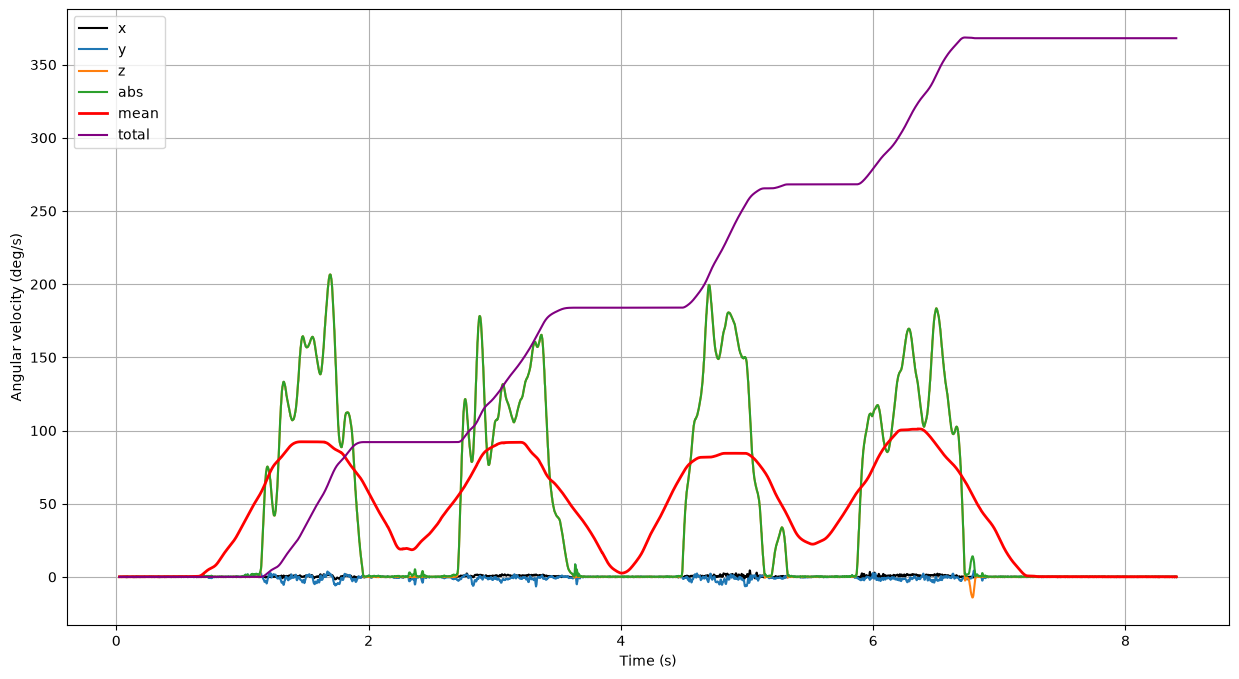

,Time (s),Gyroscope x (rad/s),Gyroscope y (rad/s),Gyroscope z (rad/s),Absolute (rad/s),Gyroscope x (deg/s),Gyroscope y (deg/s),Gyroscope z (deg/s),Absolute (deg/s),Absolute mean (deg/s),Rotation z (deg)
0,0.025148,-0.000840,0.000076,-0.000305,0.000897,-0.048125,0.004375,-0.0175,0.051395,0.109625,-0.000000
1,0.027149,-0.000840,0.000076,-0.000305,0.000897,-0.048125,0.004375,-0.0175,0.051395,0.109406,-0.000035
2,0.029143,-0.000840,0.000076,-0.000305,0.000897,-0.048125,0.004375,-0.0175,0.051395,0.109392,-0.000070
3,0.031137,-0.000840,0.000076,-0.000305,0.000897,-0.048125,0.004375,-0.0175,0.051395,0.109361,-0.000105
4,0.033132,0.000382,0.001909,-0.000305,0.001971,0.021875,0.109375,-0.0175,0.112906,0.109462,-0.000140
...,...,...,...,...,...,...,...,...,...,...,...
4185,8.394611,0.000993,-0.000535,-0.001527,0.001898,0.056875,-0.030625,-0.0875,0.108761,0.115632,368.050294
4186,8.396608,-0.000229,0.001909,-0.000916,0.002130,-0.013125,0.109375,-0.0525,0.122030,0.115533,368.050189
4187,8.398606,-0.000840,0.001298,-0.000916,0.001797,-0.048125,0.074375,-0.0525,0.102975,0.115716,368.050085
4188,8.400604,0.002214,-0.002367,0.000916,0.003368,0.126875,-0.135625,0.0525,0.192997,0.115681,368.050189


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('./Data/Raw Data.csv')
# plt.plot(df['Time (s)'], df['Gyroscope x (rad/s)'],'k')
# plt.plot(df['Time (s)'],df['Gyroscope y (rad/s)'])
# plt.plot(df['Time (s)'],df['Gyroscope z (rad/s)'])
# plt.plot(df['Time (s)'],df['Absolute (rad/s)'])
# plt.legend(['x','y','z','abs'])
rad_to_deg = 180 / np.pi
df['Gyroscope x (deg/s)'] = df['Gyroscope x (rad/s)'] * rad_to_deg
df['Gyroscope y (deg/s)'] = df['Gyroscope y (rad/s)'] * rad_to_deg
df['Gyroscope z (deg/s)'] = df['Gyroscope z (rad/s)'] * rad_to_deg
df['Absolute (deg/s)'] = df['Absolute (rad/s)'] * rad_to_deg
time_index = pd.to_timedelta(df['Time (s)'], unit='s')

df['Absolute mean (deg/s)'] = (
    df.set_index(time_index)['Absolute (deg/s)']
      .rolling('1s', center=True)
      .mean()
      .to_numpy()
)
plt.figure(figsize=(15,8))
plt.plot(df['Time (s)'], df['Gyroscope x (deg/s)'], 'k')
plt.plot(df['Time (s)'], df['Gyroscope y (deg/s)'])
plt.plot(df['Time (s)'], df['Gyroscope z (deg/s)'])
plt.plot(df['Time (s)'], df['Absolute (deg/s)'])

plt.plot(
    df['Time (s)'],
    df['Absolute mean (deg/s)'],
    color='red',
    linewidth=2,
    label='0.5 s moving average'
)

dt = df['Time (s)'].diff().fillna(0)

# Z-akselin kulmanopeus asteina sekunnissa
z_angular_velocity = df['Gyroscope z (deg/s)']

# Arvioitu kääntymiskulma asteina
df['Rotation z (deg)'] = (
    z_angular_velocity * dt
).cumsum()

print(f'Z-akselin lopullinen kääntymiskulma: '
      f'{df["Rotation z (deg)"].iloc[-1]:.2f} deg')
plt.plot(
    df['Time (s)'],
    df['Rotation z (deg)'],
    color='purple',
    label='Rotation around z-axis'
)
plt.xlabel('Time (s)')
plt.ylabel('Angular velocity (deg/s)')
plt.legend(['x','y','z','abs', 'mean', 'total'])
plt.grid()
plt.show()
df
